In [1]:
import copy
from itertools import product
from collections import Counter
import bisect
import os
import pickle
import numpy as np
from operator import itemgetter
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from scipy.optimize import minimize
import networkx as nx
import matplotlib.pyplot as plt
from numpy import random
from collections import namedtuple
from qiskit import transpile
from qiskit_ibm_runtime.fake_provider import FakeFez      # pick any fake device with enough qubits
from qiskit_aer.primitives import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.primitives import StatevectorSampler

In [2]:
def create_qaoa(graph, num_layers=1):

    #insert edges and nodes
    pqc=QuantumCircuit(n)
    # QAOA circuits start with 
    pqc.h(range(n))

    h = nx.get_node_attributes(graph, "weight")
    J = nx.get_edge_attributes(graph, "weight")
    params={}

    # adding layers 
    for l in range(num_layers):
        
        gamma_label=f'g_{l}'     
        params[gamma_label]= Parameter(gamma_label)    
        
        beta_label=f'b_{l}' 
        params[beta_label]= Parameter(beta_label)    

        pqc.barrier()
        for i in h.keys():
            pqc.rz(h[i]*params[gamma_label], i)
        
        for i, j in J.keys():                
            pqc.cx(i, j)
            pqc.rz(J[i,j]*params[gamma_label], j)
            pqc.cx(i, j)

        #Mixer Hamiltonian
        pqc.barrier()
        for i in range(n):
            pqc.rx(params[beta_label], i)
        
        #end of the layer
        pqc.barrier()

    pqc.measure_all()
    return pqc

def init_params_uni(circuit):
    parameters = random.uniform(-np.pi / 2, np.pi / 2, circuit.num_parameters)
    return parameters

def init_params_lin(circuit):
    parameters = np.linspace(-np.pi / 2, np.pi / 2, circuit.num_parameters)
    return parameters

def init_params_tri(circuit):
    parameters = random.triangular(-np.pi / 2, 0.0, np.pi / 2, circuit.num_parameters)
    return parameters

param_funcs = [init_params_lin, init_params_tri, init_params_uni]

In [3]:
seed = 1224
random.seed(seed)
n = 12

fake_device = FakeFez()                           # local object holding the device's calibration data
noisy_backend = AerSimulator.from_backend(fake_device)   # local simulator with that device's noise model, basis gates and coupling map

sampler = SamplerV2.from_backend(noisy_backend, seed=1224)
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=noisy_backend)

barabasi_albert_g = nx.barabasi_albert_graph(n=n, m=1, seed=seed)

In [4]:
def assign_uniform_weights(graph):
    for u, v in graph.edges():
        graph[u][v]["weight"] = random.uniform(-1,1)
    for node in graph.nodes():
        graph.nodes[node]["weight"] = random.uniform(-1,1)
    return graph

def assign_random_weights(graph):
    seq = [-1,1]
    for u, v in graph.edges():
        graph[u][v]["weight"] = random.choice(seq)
    for node in graph.nodes():
        graph.nodes[node]["weight"] = random.choice(seq)
    return graph

def assign_gauss_weights(graph):
    for u, v in graph.edges():
        graph[u][v]["weight"] = np.random.normal(loc=0.0, scale=1.0)
    for node in graph.nodes():
        graph.nodes[node]["weight"] = np.random.normal(loc=0.0, scale=1.0)
    return graph

/tmp/ipykernel_8019/2377321089.py:23: UserWarning: 

The arrowsize keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(G, pos, width=1.5, edge_color="gray",


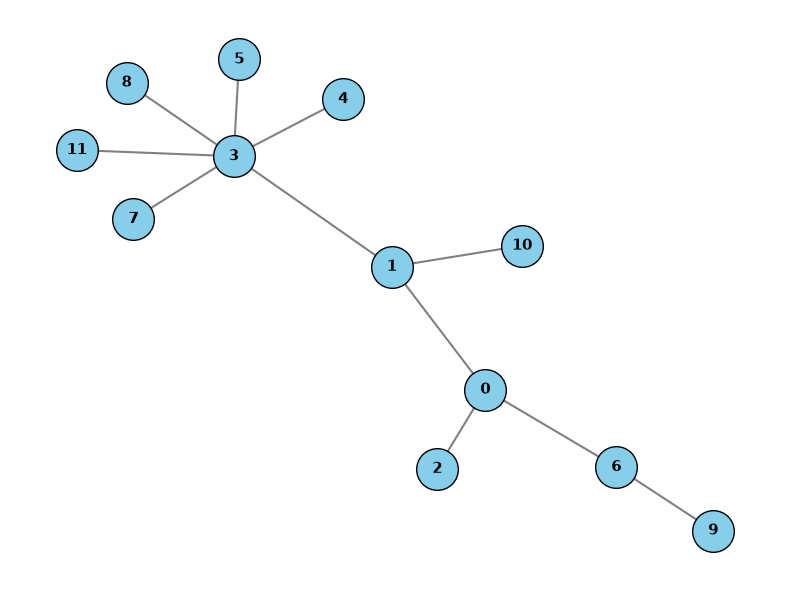

In [5]:
import networkx as nx
import matplotlib.pyplot as plt


def visualize_graph(G, layout="spring", node_color="skyblue", node_size=900,
                    show_weights=True, title=None, save_path=None, seed=42):
    layouts = {
        "spring": lambda g: nx.spring_layout(g, seed=seed),
        "circular": nx.circular_layout,
        "kamada_kawai": nx.kamada_kawai_layout,
        "shell": nx.shell_layout,
        "spectral": nx.spectral_layout,
        "random": lambda g: nx.random_layout(g, seed=seed),
    }
    if layout not in layouts:
        raise ValueError(f"Unknown layout '{layout}'. Choose from {list(layouts)}")
    pos = layouts[layout](G)

    fig, ax = plt.subplots(figsize=(8, 6))

    nx.draw_networkx_nodes(G, pos, node_color=node_color, node_size=node_size,
                           edgecolors="black", ax=ax)
    nx.draw_networkx_edges(G, pos, width=1.5, edge_color="gray",
                           arrows=G.is_directed(), arrowsize=20, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=11, font_weight="bold", ax=ax)

    # Edge weight labels (skipped for multigraphs, where edges are keyed)
    if show_weights and not G.is_multigraph():
        edge_labels = nx.get_edge_attributes(G, "weight")
        if edge_labels:
            nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax)

    if title:
        ax.set_title(title)
    ax.axis("off")
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.close(fig)
    else:
        plt.show()


# Usage with your own graph:
# visualize_graph(G)
# visualize_graph(G, layout="kamada_kawai", title="My Graph", save_path="graph.png")
visualize_graph(barabasi_albert_g)

In [6]:
# List of (node, degree) sorted by degree, highest first
def sort_stats(graph):
    sorted_degrees = sorted(graph.degree(), key=lambda x: x[1], reverse=True)

    neighbors_by_weight = {
        n: sorted(
            ((nbr, data.get("weight", 1)) for nbr, data in graph[n].items()),
            key=lambda x: abs(x[1]),
            reverse=False,
        )
        for n in graph
    }

    return sorted_degrees, neighbors_by_weight

In [7]:
sort_stats(barabasi_albert_g)

([(3, 6),
  (0, 3),
  (1, 3),
  (6, 2),
  (2, 1),
  (4, 1),
  (5, 1),
  (7, 1),
  (8, 1),
  (9, 1),
  (10, 1),
  (11, 1)],
 {0: [(1, 1), (2, 1), (6, 1)],
  1: [(0, 1), (3, 1), (10, 1)],
  2: [(0, 1)],
  3: [(1, 1), (4, 1), (5, 1), (7, 1), (8, 1), (11, 1)],
  4: [(3, 1)],
  5: [(3, 1)],
  6: [(0, 1), (9, 1)],
  7: [(3, 1)],
  8: [(3, 1)],
  9: [(6, 1)],
  10: [(1, 1)],
  11: [(3, 1)]})

In [8]:
def safe_remove_edge(graph, u, v):
    """Remove (u, v) unless doing so disconnects the graph. Returns True if removed."""
    if not graph.has_edge(u, v):
        return False                      # already gone (e.g. removed from the other endpoint)
    data = dict(graph.edges[u, v])        # keep weight and other attributes for restoring
    graph.remove_edge(u, v)
    if nx.is_connected(graph):
        return True
    graph.add_edge(u, v, **data)          # it was a bridge: put it back
    return False


def ordered_remove_edge(graph, sorted_degrees, neighbors_by_weight, num_edges, num_nodes):
    for i in range(min(num_nodes, len(sorted_degrees))):
        node = sorted_degrees[i][0]
        target = min(sorted_degrees[i][1], num_edges)
        removed = 0

        # walk down the weight-sorted list, skipping edges that can't be cut
        for nbr, _ in neighbors_by_weight[node]:
            if removed >= target:
                break
            if safe_remove_edge(graph, node, nbr):
                removed += 1
    return graph


def random_remove_edge(graph, sorted_degrees, neighbors_by_weight, num_edges, num_nodes):
    for i in range(min(num_nodes, len(sorted_degrees))):
        node = sorted_degrees[i][0]
        target = min(sorted_degrees[i][1] + 1, num_edges)
        candidates = [nbr for nbr, _ in neighbors_by_weight[node]]
        random.shuffle(candidates)
        removed = 0

        for nbr in candidates:
            if removed >= target:
                break
            if safe_remove_edge(graph, node, nbr):
                removed += 1
    return graph

In [ ]:
all_graphs = []
key = []
original_graphs = []

def make_graphs(method):
    for pref in range(1, 4):
        temp_graph = nx.barabasi_albert_graph(n=n, m=pref, seed=seed)
        original_graphs.append(temp_graph)
        weighted_graph = method(copy.deepcopy(temp_graph))
        degrees, neighbors = sort_stats(weighted_graph)
        all_graphs.append(weighted_graph)
        key.append((pref, "uniform", "original", 0, 0))
        
        for nodes in range(1, 3):
            for edges in range(1, 3):
                all_graphs.append(ordered_remove_edge(copy.deepcopy(weighted_graph), degrees, neighbors, edges, nodes))
                key.append((pref, "uniform", "ordered", nodes, edges))

                all_graphs.append(random_remove_edge(copy.deepcopy(weighted_graph), degrees, neighbors, edges, nodes))
                key.append((pref, "uniform", "random", nodes, edges))

In [10]:
make_graphs(assign_gauss_weights)
make_graphs(assign_uniform_weights)
make_graphs(assign_random_weights)

In [11]:
print(all_graphs)
print(key)
print(original_graphs)

[<networkx.classes.graph.Graph object at 0x794ff670aa50>, <networkx.classes.graph.Graph object at 0x794ff6a5a330>, <networkx.classes.graph.Graph object at 0x79507532a270>, <networkx.classes.graph.Graph object at 0x794ff6708a40>, <networkx.classes.graph.Graph object at 0x794ff670b410>, <networkx.classes.graph.Graph object at 0x794ff670bf20>, <networkx.classes.graph.Graph object at 0x794ff67087d0>, <networkx.classes.graph.Graph object at 0x794ff68fdf10>, <networkx.classes.graph.Graph object at 0x794ff68fc650>, <networkx.classes.graph.Graph object at 0x794ff6708d10>, <networkx.classes.graph.Graph object at 0x794ff68ffb90>, <networkx.classes.graph.Graph object at 0x794ff670ad50>, <networkx.classes.graph.Graph object at 0x794ff670b3b0>, <networkx.classes.graph.Graph object at 0x794ff6709ee0>, <networkx.classes.graph.Graph object at 0x794ff68ff410>, <networkx.classes.graph.Graph object at 0x794ff68fc320>, <networkx.classes.graph.Graph object at 0x794ff68fe7e0>, <networkx.classes.graph.Graph 

In [12]:
# 1. Backend and connectivity graph
coupling_map = fake_device.coupling_map            # CouplingMap (directed edge list)

G = nx.Graph()
G.add_nodes_from(range(fake_device.num_qubits))    # keeps any isolated qubits
G.add_edges_from(coupling_map.get_edges())     # duplicates (a,b)/(b,a) merge in an undirected Graph

print(f"{G.number_of_nodes()} qubits, {G.number_of_edges()} couplings")

# 2. Nodes sorted by degree (highest first, ties broken by qubit index)
sorted_degrees = sorted(G.degree(), key=lambda x: (-x[1], x[0]))
for q, d in sorted_degrees:
    print(f"qubit {q}: degree {d}")

156 qubits, 176 couplings
qubit 3: degree 3
qubit 7: degree 3
qubit 11: degree 3
qubit 21: degree 3
qubit 23: degree 3
qubit 25: degree 3
qubit 27: degree 3
qubit 29: degree 3
qubit 31: degree 3
qubit 33: degree 3
qubit 41: degree 3
qubit 43: degree 3
qubit 45: degree 3
qubit 47: degree 3
qubit 49: degree 3
qubit 51: degree 3
qubit 53: degree 3
qubit 61: degree 3
qubit 63: degree 3
qubit 65: degree 3
qubit 67: degree 3
qubit 69: degree 3
qubit 71: degree 3
qubit 73: degree 3
qubit 81: degree 3
qubit 83: degree 3
qubit 85: degree 3
qubit 87: degree 3
qubit 89: degree 3
qubit 91: degree 3
qubit 93: degree 3
qubit 101: degree 3
qubit 103: degree 3
qubit 105: degree 3
qubit 107: degree 3
qubit 109: degree 3
qubit 111: degree 3
qubit 113: degree 3
qubit 121: degree 3
qubit 123: degree 3
qubit 125: degree 3
qubit 127: degree 3
qubit 129: degree 3
qubit 131: degree 3
qubit 133: degree 3
qubit 143: degree 3
qubit 147: degree 3
qubit 151: degree 3
qubit 1: degree 2
qubit 2: degree 2
qubit 4: de

In [13]:
def f(bits, h, J):    
    bitstring = [1 if bit == "0" else -1 for bit in bits]
    return (sum(h[i] * bitstring[i] for i in h) + sum(weight * bitstring[i] * bitstring[j] for (i,j), weight in J.items()))

In [14]:
import numpy as np
from itertools import product


def solve_exact(graph, f, weight="weight", verbose=True):
    """
    Extract h and J from a NetworkX graph, evaluate every bitstring with
    f(bits, h, J), and return the exact global minimum.
    """
    n = graph.number_of_nodes()
    h = {i: graph.nodes[i].get(weight, 0.0) for i in graph.nodes}
    J = {(min(u, v), max(u, v)): d.get(weight, 1.0) for u, v, d in graph.edges(data=True)}

    bitstrings, f_list = [], []
    for bits in product("01", repeat=n):
        x = "".join(bits)
        bitstrings.append(x)
        f_list.append(f(x, h, J))

    f_arr = np.array(f_list)
    min_cost = f_arr.min()
    best = [b for b, v in zip(bitstrings, f_list) if np.isclose(v, min_cost)]

    if verbose:
        print(f"Best bitstring(s): {best} | value: {min_cost:.1f}")

    return {"h": h, "J": J, "min_cost": min_cost, "max_cost": f_arr.max(),
            "best_bitstrings": best, "bitstrings": bitstrings, "costs": f_list}

In [15]:
for graph in original_graphs:
    solve_exact(graph, f)

Best bitstring(s): ['011011111001', '100100000110'] | value: -11.0
Best bitstring(s): ['001001111111', '011001111011', '011001111111', '100110000000', '100110000100', '110110000000'] | value: -12.0
Best bitstring(s): ['011001110010', '011001111010', '011001111100', '100110000011', '100110000101', '100110001101'] | value: -13.0
Best bitstring(s): ['011011111001', '100100000110'] | value: -11.0
Best bitstring(s): ['001001111111', '011001111011', '011001111111', '100110000000', '100110000100', '110110000000'] | value: -12.0
Best bitstring(s): ['011001110010', '011001111010', '011001111100', '100110000011', '100110000101', '100110001101'] | value: -13.0
Best bitstring(s): ['011011111001', '100100000110'] | value: -11.0
Best bitstring(s): ['001001111111', '011001111011', '011001111111', '100110000000', '100110000100', '110110000000'] | value: -12.0
Best bitstring(s): ['011001110010', '011001111010', '011001111100', '100110000011', '100110000101', '100110001101'] | value: -13.0


In [16]:
results_path = "qaoa_noisy_results.pkl"

# Load earlier progress if the file exists
if os.path.exists(results_path):
    with open(results_path, "rb") as file:
        all_results = pickle.load(file)
else:
    all_results = []

completed_run_keys = {
    (r["graph_index"], r["num_layers"], r["init_name"]) for r in all_results
}


def save_results():
    temporary_path = results_path + ".tmp"
    with open(temporary_path, "wb") as file:
        pickle.dump(all_results, file)
    os.replace(temporary_path, results_path)     # swap in only after the write finished


for graph_index, graph in enumerate(all_graphs):
    h = nx.get_node_attributes(graph, "weight")
    J = nx.get_edge_attributes(graph, "weight")
    n = graph.number_of_nodes()

    all_bitstrings = ["".join(b) for b in product("01", repeat=n)]
    all_costs = [f(bits, h, J) for bits in all_bitstrings]
    exact_global_minimum = min(all_costs)
    exact_best_bitstring = all_bitstrings[int(np.argmin(all_costs))]

    for num_layers in range(5, 11):
        logical_pqc = create_qaoa(graph=graph, num_layers=num_layers)
        pqc = pass_manager.run(logical_pqc)

        circuit_stats = {
            "logical_depth": logical_pqc.depth(),
            "logical_two_qubit_gates": logical_pqc.num_nonlocal_gates(),
            "transpiled_depth": pqc.depth(),
            "transpiled_two_qubit_gates": pqc.num_nonlocal_gates(),
            "transpiled_gate_counts": dict(pqc.count_ops()),
        }

        for init_param in param_funcs:
            run_key = (graph_index, num_layers, init_param.__name__)
            if run_key in completed_run_keys:
                continue                                   # finished in an earlier session
            print(
                f"Simulating graph {graph_index + 1}/{len(all_graphs)} | "
                f"layers {num_layers}/5 | init {init_param.__name__} | "
                f"{n} qubits, {pqc.num_parameters} parameters, depth {pqc.depth()}"
            )

            x0 = init_param(pqc)
            evaluations = []

            def logged_objective(angles):
                counts = (
                    sampler.run([pqc.assign_parameters(angles)], shots=1024)
                    .result()[0].data.meas.get_counts()
                )
                counts = {b[::-1]: c for b, c in counts.items()}
                ev = sum(f(b, h, J) * c for b, c in counts.items()) / sum(counts.values())
                evaluations.append({"angles": np.array(angles), "ev": ev, "counts": counts})
                return ev

            result = minimize(logged_objective, x0, method="COBYLA", options={"maxiter": 200})

            all_results.append({
                "graph_index": graph_index,
                "num_layers": num_layers,
                "init_name": init_param.__name__,
                "parameter_names": [p.name for p in pqc.parameters],
                "x0": x0,
                "result": result,
                "evaluations": evaluations,
                "all_bitstrings": all_bitstrings,
                "all_costs": all_costs,
                "exact_global_minimum": exact_global_minimum,
                "exact_best_bitstring": exact_best_bitstring,
                **circuit_stats
            })
            completed_run_keys.add(run_key)
            save_results()                                 # checkpoint after every run

Simulating graph 1/81 | layers 5/5 | init init_params_lin | 12 qubits, 10 parameters, depth 559
Simulating graph 1/81 | layers 5/5 | init init_params_tri | 12 qubits, 10 parameters, depth 559


KeyboardInterrupt: 

In [ ]:
import os
import pickle
import numpy as np
import pandas as pd


def evaluate_after_training(all_graphs, key, f, create_qaoa, pass_manager, sampler,
                            results_path="qaoa_noisy_results.pkl",
                            output_path="pruned_on_original.csv",
                            shots=4096, use_best_evaluated=False, weight="weight"):
    """
    Load all finished runs from results_path, apply each run's learned angles to
    its ORIGINAL full graph, and return a DataFrame comparing against the exact optimum.

    all_graphs, key : same lists produced by make_graphs (must match the training session).
    """
    with open(results_path, "rb") as file:
        all_results = pickle.load(file)
    print(f"Loaded {len(all_results)} runs from {results_path}")

    if len(all_graphs) != len(key):
        raise ValueError("all_graphs and key must be the same length")

    # Map each graph index to its original graph's index
    orig_of, current = [], None
    for i, k in enumerate(key):
        if k[2] == "original":
            current = i
        orig_of.append(current)

    def get_h_J(g):
        h = {i: g.nodes[i].get(weight, 0.0) for i in g.nodes}
        J = {(min(u, v), max(u, v)): d.get(weight, 1.0) for u, v, d in g.edges(data=True)}
        return h, J

    # Per original graph: coefficients and exact optimum (computed once)
    problems = {}
    for oi in sorted(set(orig_of)):
        g = all_graphs[oi]
        h, J = get_h_J(g)
        n = g.number_of_nodes()
        costs = {}
        for i in range(2 ** n):
            b = format(i, f"0{n}b")
            costs[b] = f(b, h, J)
        problems[oi] = {"h": h, "J": J, "exact_min": min(costs.values())}

    circuit_cache, rows = {}, []
    for idx, run in enumerate(all_results):
        gi, layers = run["graph_index"], run["num_layers"]
        oi = orig_of[gi]
        h, J, exact_min = problems[oi]["h"], problems[oi]["J"], problems[oi]["exact_min"]

        # Transpile the original circuit once per (graph, layers)
        if (oi, layers) not in circuit_cache:
            circuit_cache[(oi, layers)] = pass_manager.run(
                create_qaoa(graph=all_graphs[oi], num_layers=layers))
        pqc = circuit_cache[(oi, layers)]

        angles = (min(run["evaluations"], key=lambda e: e["ev"])["angles"]
                  if use_best_evaluated else run["result"].x)

        by_name = {p.name: p for p in pqc.parameters}
        values = dict(zip(run["parameter_names"], angles))
        if set(by_name) != set(values):
            raise ValueError(f"Parameter mismatch at graph {gi}, layers {layers}: "
                             f"{sorted(set(by_name) ^ set(values))}")
        bound = pqc.assign_parameters({by_name[k]: v for k, v in values.items()})

        counts = sampler.run([bound], shots=shots).result()[0].data.meas.get_counts()
        counts = {b[::-1]: c for b, c in counts.items()}
        total = sum(counts.values())
        costs = {b: f(b, h, J) for b in counts}
        expectation = sum(costs[b] * c for b, c in counts.items()) / total
        best_sampled = min(costs, key=costs.get)

        k = key[gi]
        rows.append({
            "graph_index": gi, "original_index": oi,
            "pref": k[0], "method": k[2], "nodes_pruned": k[3], "edges_pruned": k[4],
            "edges_removed": all_graphs[oi].number_of_edges() - all_graphs[gi].number_of_edges(),
            "num_layers": layers, "init_name": run["init_name"],
            "ev_on_pruned": run["result"].fun,
            "ev_on_original": expectation,
            "best_sampled": best_sampled,
            "best_sampled_value": costs[best_sampled],
            "exact_min": exact_min,
            "gap": expectation - exact_min,
            "found_optimum": np.isclose(costs[best_sampled], exact_min),
        })
        print(f"[{idx + 1}/{len(all_results)}] graph {gi}, layers {layers}, "
              f"{run['init_name']}: gap {expectation - exact_min:.4f}")

    df = pd.DataFrame(rows)

    # Baseline: the unpruned run with the same original graph, layers, and init
    base = (df[df.method == "original"]
            .set_index(["original_index", "num_layers", "init_name"])[["gap"]]
            .add_prefix("baseline_"))
    df = df.join(base, on=["original_index", "num_layers", "init_name"])
    df["gap_increase"] = df["gap"] - df["baseline_gap"]   # positive = pruning hurt

    df.to_csv(output_path, index=False)
    print(f"Saved {len(df)} rows to {output_path}")
    return df

In [ ]:
df = evaluate_after_training(all_graphs, key, f, create_qaoa, pass_manager, sampler)

print(df[df.method != "original"]
      .groupby(["pref", "method", "nodes_pruned", "edges_pruned"])
      [["gap", "gap_increase", "found_optimum"]].mean())